# CS4372 Assignment 4

Summarization, translation, question answering and text generation on *A Tale of Two Cities*.

Run on a GPU runtime (a free T4 is enough). Project Gutenberg tends to block Colab with HTTP 503, so upload `data/pg98` and `data/pg61887` from the repo into `./data/` before running.

In [ ]:
%pip install -q rouge bert-score evaluate sacrebleu

In [ ]:
import math
import pathlib
import re
import string
import subprocess
import urllib.request
from collections import defaultdict
from operator import add

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import load_dataset
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer, pipeline

## Summarization

In [ ]:
ttc_url = "https://www.gutenberg.org/cache/epub/98/pg98.txt"
ttc_path = pathlib.Path("./data/pg98")
ttc_path.parent.mkdir(parents=True, exist_ok=True)
# Gutenberg often blocks Colab IPs (HTTP 503); if so, upload data/ from the repo first
if not ttc_path.exists():
    ttc_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(ttc_url, ttc_path)

# The book proper begins at line 100 and the Gutenberg licence starts at line 15933
with open(ttc_path, "r") as file:
    ttc_strings = file.readlines()[99:15932]

In [ ]:
ttc_chapters = []
curr_chapter = []
for line in ttc_strings:
    if line.startswith("Book the"):
        continue
    if not re.match(r"CHAPTER [IVXL]+\.$", line.strip()):
        curr_chapter.append(line)
    else:
        ttc_chapters.append(curr_chapter)
        curr_chapter = []

ttc_chapters.append(curr_chapter)

ttc_chapters.pop(0)

ttc_chapters = ["".join(ch).replace("\n", " ").strip() for ch in ttc_chapters]

model_name = "facebook/bart-large-cnn"
device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(device).eval()

ttc_token_lengths = [
    len(tokenizer(ch, add_special_tokens=False)["input_ids"]) for ch in ttc_chapters
]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


In [ ]:
# split each chapter into even chunks, summarize each one, and join the results
def summarize(text, max_chunk_tokens=1000):
    ids = tokenizer(text, add_special_tokens=False)["input_ids"]
    n_chunks = math.ceil(len(ids) / max_chunk_tokens)
    size = math.ceil(len(ids) / n_chunks)
    chunks = [tokenizer.decode(ids[i : i + size]) for i in range(0, len(ids), size)]

    batch = tokenizer(
        chunks, return_tensors="pt", padding=True, truncation=True, max_length=1024
    ).to(device)
    with torch.inference_mode():
        out = model.generate(
            **batch, num_beams=4, min_new_tokens=30, max_new_tokens=128
        )
    return " ".join(tokenizer.batch_decode(out, skip_special_tokens=True))

In [ ]:
ttc_summaries = [summarize(ch) for ch in ttc_chapters]

# reference chapter summaries to test against with ROUGE and BERTScore
booksum = load_dataset("kmfoda/booksum", split="train+validation+test").to_pandas()
booksum["title"] = booksum["book_id"].str.split(".").str[0]

ttc_refs = booksum[
    (booksum["title"] == "A Tale of Two Cities") & ~booksum["is_aggregate"]
].copy()
ttc_refs[["book", "chapter_num"]] = (
    ttc_refs["book_id"].str.extract(r"book (\d+)\.chapter (\d+)$").astype(int)
)
# (book, chapter) -> list of reference summaries, in reading order,
# ttc_refs.iloc[i] <-> ttc_chapters[i]
ttc_refs = ttc_refs.groupby(["book", "chapter_num"])["summary_text"].apply(list)

ttc_refs_list = ttc_refs.tolist()
assert len(ttc_refs_list) == len(ttc_chapters)

# Evaluation
from bert_score import BERTScorer
from rouge import Rouge

rouge = Rouge()

[transformers] Both `max_new_tokens` (=128) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `min_new_tokens` (=30) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=128) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `min_new_tokens` (=30) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=128) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `min_new_tokens` (=30) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (80 outputs left out)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `min_new_tokens` (=30) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=128) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `min_new_tokens` (=30) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


In [ ]:
# Rouge.get_scores(hyps, refs) pairs hyps[i] with refs[i], so repeat the summary once
# per reference.
def get_rouge_score(summary, refs):
    scores = rouge.get_scores([summary] * len(refs), refs)
    return {
        m: max(s[m]["f"] for s in scores) for m in ["rouge-1", "rouge-2", "rouge-l"]
    }

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


      rouge-1  rouge-2  rouge-l  bertscore  tokens
1.1     0.205    0.044    0.182      0.002    1288
1.2     0.223    0.058    0.205      0.046    2988
1.3     0.357    0.182    0.357      0.118    2198
1.4     0.272    0.066    0.242     -0.006    6088
1.5     0.260    0.065    0.238      0.058    5720
1.6     0.290    0.060    0.282     -0.008    5655
2.1     0.299    0.070    0.299      0.155    3476
2.2     0.293    0.072    0.283      0.094    3344
2.3     0.256    0.068    0.243     -0.029    6773
2.4     0.269    0.079    0.251      0.056    3415
2.5     0.223    0.051    0.215     -0.048    3124
2.6     0.244    0.057    0.232     -0.061    6481
2.7     0.252    0.052    0.227      0.008    4466
2.8     0.333    0.108    0.304      0.112    2756
2.9     0.267    0.105    0.258      0.009    5853
2.10    0.290    0.068    0.283      0.116    4065
2.11    0.214    0.048    0.203      0.017    2127
2.12    0.224    0.037    0.218     -0.083    3866
2.13    0.270    0.042    0.246

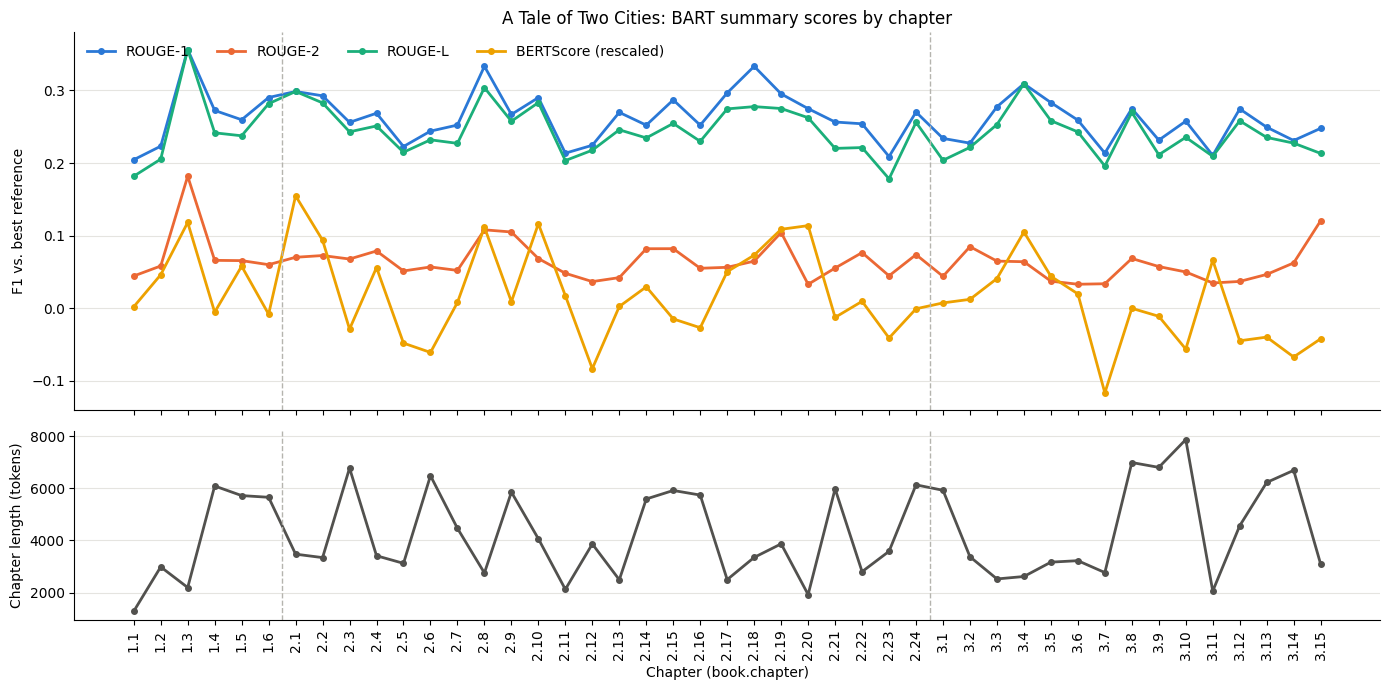

In [ ]:
rouge_scores_out = [
    get_rouge_score(ttc_summaries[i], ttc_refs_list[i])
    for i in range(len(ttc_chapters))
]

# Passing a list of reference lists scores each summary against all of its references
# and keeps the best. Rescaling spreads the scores out; raw BERTScore F1 sits around 0.85.
scorer = BERTScorer(lang="en", rescale_with_baseline=True)
bert_p, bert_r, bert_f1 = scorer.score(ttc_summaries, ttc_refs_list)

results = pd.DataFrame(rouge_scores_out)
results["bertscore"] = bert_f1.tolist()
results["tokens"] = ttc_token_lengths
results.index = [f"{book}.{ch}" for book, ch in ttc_refs.index]
print(results.round(3))
print(results.mean().round(3))

fig, (ax_scores, ax_tokens) = plt.subplots(
    2, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)
x = range(len(results))
for col, label, color in [
    ("rouge-1", "ROUGE-1", "#2a78d6"),
    ("rouge-2", "ROUGE-2", "#eb6834"),
    ("rouge-l", "ROUGE-L", "#1baf7a"),
    ("bertscore", "BERTScore (rescaled)", "#eda100"),
]:
    ax_scores.plot(
        x, results[col], label=label, color=color, linewidth=2, marker="o", markersize=4
    )
ax_scores.set_ylabel("F1 vs. best reference")
ax_scores.set_title("A Tale of Two Cities: BART summary scores by chapter")
ax_scores.legend(loc="upper left", ncols=4, frameon=False)

ax_tokens.plot(
    x, results["tokens"], color="#52514e", linewidth=2, marker="o", markersize=4
)
ax_tokens.set_ylabel("Chapter length (tokens)")
ax_tokens.set_xlabel("Chapter (book.chapter)")
ax_tokens.set_xticks(list(x), results.index, rotation=90)

for ax in (ax_scores, ax_tokens):
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    # mark where books 2 and 3 start
    for start in (6, 30):
        ax.axvline(start - 0.5, color="#b5b4ae", linewidth=1, linestyle="--")

fig.tight_layout()
fig.savefig("summary_scores.png", dpi=150)
plt.show()

# Save the scores and the summaries themselves for the report
results.to_csv("summary_results.csv", index_label="chapter")
pd.DataFrame(
    {"chapter": results.index, "summary": ttc_summaries, "references": ttc_refs_list}
).to_json("summaries.json", orient="records", indent=1)
results.rename(
    columns={
        "rouge-1": "ROUGE-1",
        "rouge-2": "ROUGE-2",
        "rouge-l": "ROUGE-L",
        "bertscore": "BERTScore",
        "tokens": "Tokens",
    }
).rename_axis("Ch.").to_latex(
    "summary_results.tex",
    float_format="%.3f",
    longtable=True,
    caption="BART-large-CNN chapter summaries scored against the best-matching "
    "BookSum reference (F1). BERTScore is rescaled with its baseline.",
    label="tab:summary",
)

## Translation

In [ ]:
import evaluate
from transformers import AutoModelForCausalLM

N_CHAPTERS = 5  # the whole book is ~450 chunks, so only translate the first few chapters

### Spanish reference translation (Gregorio Lafuerza)

In [ ]:
es_url = "https://www.gutenberg.org/cache/epub/61887/pg61887.txt"
es_path = pathlib.Path("./data/pg61887")
# Gutenberg often blocks Colab IPs (HTTP 503); if so, upload data/ from the repo first
if not es_path.exists():
    es_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(es_url, es_path)

# The book proper begins at line 117; line 17310 is "FIN", followed by the table of contents
with open(es_path, "r") as file:
    es_strings = file.readlines()[116:17309]

In [ ]:
es_chapters = []
curr_chapter = []
for line in es_strings:
    if line.startswith("LIBRO"):
        continue
    if not re.match(r"[IVXL]+\.?$", line.strip()):
        curr_chapter.append(line)
    else:
        es_chapters.append(curr_chapter)
        curr_chapter = []

es_chapters.append(curr_chapter)

es_chapters.pop(0)

es_chapters = ["".join(ch).replace("\n", " ").strip() for ch in es_chapters]

translation_pairs = list(zip(ttc_chapters, es_chapters))

### Model

In [ ]:
mt_name = "pfnet/plamo-3-translate-0.8b"
mt_tokenizer = AutoTokenizer.from_pretrained(mt_name, trust_remote_code=True)
mt_tokenizer.padding_side = "left"  # needed for batched generation, per the model card
# The T4 has no native bfloat16, and float16 can overflow in models trained in
# bfloat16. At 0.8B parameters, float32 fits easily (~3.2 GB).
mt_model = AutoModelForCausalLM.from_pretrained(
    mt_name, trust_remote_code=True, dtype="float32", device_map="auto"
)

In [ ]:
def split_chunks(chapter, max_chunk_words=300):
    sentences = re.split(r"(?<=[.!?”])\s+", chapter)
    chunks, curr = [], []
    for s in sentences:
        if curr and len(" ".join(curr + [s]).split()) > max_chunk_words:
            chunks.append(" ".join(curr))
            curr = []
        curr.append(s)
    chunks.append(" ".join(curr))
    return chunks

In [ ]:
# Translate all of a chapter's chunks in one batch (the model card's
# "multiple texts at once" example), then join them back together
def translate(chapter):
    chunks = split_chunks(chapter)
    inputs = mt_tokenizer.apply_chat_template(
        [[{"role": "user", "content": c}] for c in chunks],
        source_lang="en",
        target_lang="es",
        add_generation_prompt=True,
        padding=True,
        return_dict=True,
        return_tensors="pt",
    ).to(mt_model.device)
    with torch.inference_mode():
        outputs = mt_model.generate(**inputs, do_sample=False, max_new_tokens=1024)
    # every row is padded to the same prompt length, so one slice drops all the prompts
    translations = mt_tokenizer.batch_decode(
        outputs[:, inputs["input_ids"].shape[1] :], skip_special_tokens=True
    )
    return " ".join(t.strip() for t in translations)

In [ ]:
ttc_translations = []
for i, (en, _) in enumerate(translation_pairs[:N_CHAPTERS]):
    ttc_translations.append(translate(en))
    print(f"translated chapter {i + 1}/{N_CHAPTERS}", flush=True)

translated chapter 1/5


translated chapter 2/5


translated chapter 3/5


translated chapter 4/5


translated chapter 5/5


### Evaluation

In [ ]:
# predictions is a list of strings and references a list of reference lists, one
# per prediction. chrF is reported alongside BLEU because it matches at the
# character level, which suits a loose literary reference translation better.
bleu = evaluate.load("sacrebleu")
chrf = evaluate.load("chrf")

translation_results = pd.DataFrame(
    [
        {
            "chapter": f"1.{i + 1}",
            "en_words": len(en.split()),
            "es_ref_words": len(ref.split()),
            "mt_words": len(mt.split()),
            "BLEU": bleu.compute(predictions=[mt], references=[[ref]])["score"],
            "chrF": chrf.compute(predictions=[mt], references=[[ref]])["score"],
        }
        for i, ((en, ref), mt) in enumerate(zip(translation_pairs, ttc_translations))
    ]
).set_index("chapter")

print(translation_results.round(2).to_string())
print(translation_results[["BLEU", "chrF"]].mean().round(2).to_string())

translation_results.to_csv("translation_results.csv")
# underscores in column names break LaTeX, so rename for the table only
translation_results.rename(
    columns={"en_words": "EN words", "es_ref_words": "Ref. words", "mt_words": "MT words"}
).rename_axis("Chapter").round(2).to_latex(
    "translation_results.tex",
    float_format="%.2f",
    caption="PLaMo 3 Translate 0.8B (English to Spanish) against Lafuerza's translation",
    label="tab:translation",
)

         en_words  es_ref_words  mt_words   BLEU   chrF
chapter                                                
1.1          1003          1185      1015  13.83  55.49
1.2          2015          2128      2029   8.88  53.65
1.3          1612          1665      1607  10.33  55.81
1.4          4381          4856      4363  12.06  59.26
1.5          4149          3843      4223  10.55  62.06
BLEU    11.13
chrF    57.25


## Question answering

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoModelForQuestionAnswering

# book.chapter labels: the three books have 6, 24 and 15 chapters
chapter_labels = [
    f"{book}.{ch}" for book, n in [(1, 6), (2, 24), (3, 15)] for ch in range(1, n + 1)
]

# passages are used as the base document size for tf-idf search
PASSAGE_WORDS = 200
OVERLAP = 50

passages, passage_chapter = [], []
for label, chapter in zip(chapter_labels, ttc_chapters):
    words = chapter.split()
    for start in range(0, max(len(words) - OVERLAP, 1), PASSAGE_WORDS - OVERLAP):
        passages.append(" ".join(words[start : start + PASSAGE_WORDS]))
        passage_chapter.append(label)

# TF-IDF search, one document per passage
vectorizer = TfidfVectorizer(stop_words="english", sublinear_tf=True)
doc_matrix = vectorizer.fit_transform(passages)

In [ ]:
def search(query, k=3):
    sims = cosine_similarity(vectorizer.transform([query]), doc_matrix)[0]
    top = sims.argsort()[::-1][:k]
    return [(int(i), float(sims[i])) for i in top]

In [ ]:
qa_name = "deepset/roberta-base-squad2"
qa_tokenizer = AutoTokenizer.from_pretrained(qa_name)
qa_model = AutoModelForQuestionAnswering.from_pretrained(qa_name).to(device).eval()

In [ ]:
def read(question, passage, max_answer_tokens=30):
    enc = qa_tokenizer(
        question,
        passage,
        truncation="only_second",
        max_length=512,
        return_offsets_mapping=True,
        return_tensors="pt",
    )
    offsets = enc.pop("offset_mapping")[0]
    context = torch.tensor([s == 1 for s in enc.sequence_ids(0)])  # passage tokens only
    with torch.inference_mode():
        out = qa_model(**enc.to(device))
    start_logp = out.start_logits[0].cpu().log_softmax(-1)
    end_logp = out.end_logits[0].cpu().log_softmax(-1)

    # best span with start <= end, both inside the passage, at most 30 tokens long
    span_scores = start_logp[:, None] + end_logp[None, :]
    n = span_scores.shape[0]
    valid = torch.ones(n, n, dtype=torch.bool).triu() & ~torch.ones(
        n, n, dtype=torch.bool
    ).triu(max_answer_tokens)
    valid &= context[:, None] & context[None, :]
    span_scores[~valid] = float("-inf")
    s, e = divmod(int(span_scores.argmax()), n)
    return {
        "answer": passage[int(offsets[s][0]) : int(offsets[e][1])],
        "score": float(span_scores[s, e].exp()),
    }

In [ ]:
def answer(question, k=3):
    hits = search(question, k)
    best = None
    for idx, sim in hits:
        pred = read(question, passages[idx])
        if best is None or pred["score"] > best["score"]:
            best = {**pred, "chapter": passage_chapter[idx]}
    return hits, best

In [ ]:
questions = [
    ("What is the name of the bank Mr. Lorry works for?", "Tellson's", "Tellson"),
    (
        "What number was Doctor Manette's cell in the Bastille?",
        "One Hundred and Five, North Tower",
        "One Hundred and Five",
    ),
    ("Who was tried for treason at the Old Bailey?", "Charles Darnay", "Darnay"),
    ("What does Madame Defarge do while she sits in the wine-shop?", "knits", "knit"),
    ("Who takes Darnay's place at the guillotine?", "Sydney Carton", "Carton"),
]

qa_rows = []
for question, expected, key in questions:
    hits, best = answer(question)
    qa_rows.append(
        {
            "Question": question,
            "Expected": expected,
            "Top 3 passages: ch. (cos sim)": ", ".join(
                f"{passage_chapter[i]} ({s:.2f})" for i, s in hits
            ),
            "Answer in top 3": any(key.lower() in passages[i].lower() for i, _ in hits),
            "Answer": best["answer"],
            "Answer ch.": best["chapter"],
            "Score": best["score"],
            "Correct": key.lower() in best["answer"].lower(),
        }
    )

qa_results = pd.DataFrame(qa_rows)
print(qa_results.to_string())

qa_results.to_csv("qa_results.csv", index=False)
qa_results.to_latex(
    "qa_results.tex",
    index=False,
    float_format="%.2f",
    column_format=r">{\raggedright\arraybackslash}p{3.3cm}>{\raggedright\arraybackslash}p{2.1cm}>{\raggedright\arraybackslash}p{2.6cm}>{\raggedright\arraybackslash}p{1.1cm}>{\raggedright\arraybackslash}p{2.4cm}>{\raggedright\arraybackslash}p{0.9cm}rl",
    caption="TF-IDF retrieval of the top 3 200-word passages, then answers from "
    "deepset/roberta-base-squad2",
    label="tab:qa",
)

                                                       Question                           Expected          Top 3 passages: ch. (cos sim)  Answer in top 3                 Answer Answer ch.     Score  Correct
0             What is the name of the bank Mr. Lorry works for?                          Tellson's    1.4 (0.14), 3.13 (0.14), 2.3 (0.12)             True                Tellson        2.3  0.497298     True
1        What number was Doctor Manette's cell in the Bastille?  One Hundred and Five, North Tower    3.9 (0.28), 3.10 (0.15), 3.2 (0.15)             True   One Hundred and Five        3.9  0.262321     True
2                  Who was tried for treason at the Old Bailey?                     Charles Darnay     2.2 (0.21), 2.2 (0.17), 2.2 (0.14)            False     Mr. Jerry Cruncher        2.2  0.005369    False
3  What does Madame Defarge do while she sits in the wine-shop?                              knits  2.22 (0.19), 2.15 (0.18), 2.15 (0.18)             True  taken up her

## Text generation

In [ ]:
# The chapter title is the text before the first run of spaces left by blank lines
chapter_bodies = [re.split(r"\s{2,}", ch, maxsplit=1)[1] for ch in ttc_chapters]

# GPT-2 is used for generation and GPT-2 Large scores.
gen_tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
gen_model = (
    AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device).eval()
)
ppl_model = (
    AutoModelForCausalLM.from_pretrained("openai-community/gpt2-large")
    .to(device)
    .eval()
)

SEED_WORDS = 20
NEW_TOKENS = 60

seed_chapters = ["1.2", "2.1", "2.7", "3.1", "3.5"]

In [ ]:
def generate(seed):
    inputs = gen_tokenizer(seed, return_tensors="pt").to(device)
    with torch.inference_mode():
        out = gen_model.generate(
            **inputs,
            do_sample=True,
            top_p=0.9,
            temperature=0.8,
            no_repeat_ngram_size=3,
            max_new_tokens=NEW_TOKENS,
            pad_token_id=gen_tokenizer.eos_token_id,
        )
    return gen_tokenizer.decode(
        out[0, inputs["input_ids"].shape[1] :], skip_special_tokens=True
    )

In [ ]:
def perplexity(seed, continuation):
    seed_ids = gen_tokenizer(seed, return_tensors="pt")["input_ids"]
    cont_ids = gen_tokenizer(continuation, return_tensors="pt")["input_ids"]
    ids = torch.cat([seed_ids, cont_ids], dim=1).to(device)
    labels = ids.clone()
    labels[:, : seed_ids.shape[1]] = -100
    with torch.inference_mode():
        loss = ppl_model(input_ids=ids, labels=labels).loss
    return math.exp(loss.item())

In [ ]:
torch.manual_seed(0)
gen_rows = []
for label in seed_chapters:
    words = chapter_bodies[chapter_labels.index(label)].split()
    seed = " ".join(words[:SEED_WORDS])

    generated = generate(seed)
    n_gen = len(gen_tokenizer(generated)["input_ids"])
    book_ids = gen_tokenizer(" " + " ".join(words[SEED_WORDS:]))["input_ids"][:n_gen]
    book_continuation = gen_tokenizer.decode(book_ids)

    gen_rows.append(
        {
            "Ch.": label,
            "Seed": seed,
            "Generated continuation": " ".join(generated.split()),
            "PPL (generated)": perplexity(seed, generated),
            "PPL (book)": perplexity(seed, book_continuation),
            "Book continuation": " ".join(book_continuation.split()),
        }
    )

generation_results = pd.DataFrame(gen_rows)
print(generation_results[["Ch.", "PPL (generated)", "PPL (book)"]].round(2).to_string())
print(generation_results[["PPL (generated)", "PPL (book)"]].mean().round(2).to_string())

generation_results.to_csv("generation_results.csv", index=False)
generation_results.drop(columns="Book continuation").to_latex(
    "generation_results.tex",
    index=False,
    float_format="%.2f",
    column_format=r"l>{\raggedright\arraybackslash}p{3.6cm}>{\raggedright\arraybackslash}p{7.0cm}rr",
    caption="GPT-2 continuations of 20-word seeds from the book. Perplexity is "
    "scored by GPT-2 Large on the continuation given the seed, for the generated "
    "text and for the book's own next tokens.",
    label="tab:generation",
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (2903 > 1024). Running this sequence through the model will result in indexing errors


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


   Ch.  PPL (generated)  PPL (book)
0  1.2            11.54       46.41
1  2.1            13.24       16.10
2  2.7            16.83       27.18
3  3.1             7.68       17.28
4  3.5            17.30       90.36
PPL (generated)    13.32
PPL (book)         39.47
